# Lab 6-03（選讀）：什麼時候不該微調

**目標**：同一個 IT 維運問診任務，不微調、只改 prompt 能做到多好？跟 Lab 6-01 的 LoRA 放在一起比。

**你會學到**
- 先 prompt、再 RAG、最後才微調的理由，用數字說話
- 把「值班手冊」塞進 prompt，其實就是最簡單的 RAG
- 微調真正買到的是什麼：短 prompt、小模型、穩定格式

**前置**：Lab 6-01 的 adapter（`/tmp/m6_lora_adapter`）；Ollama 的 `qwen2.5:3b`。約 3～5 分鐘，大部分時間在等 Ollama。

**對應投影片**：「微調是什麼」「Prompt、RAG、微調怎麼選」

![先判斷是不知道還是不會說，再選 prompt、RAG 或微調](images/prompt_rag_finetune.jpg)

*圖：先問問題出在「缺知識」（右，走 RAG）還是「不會照格式說」（左，先寫 prompt）。朱紅那條是本模組的路：prompt 仍不穩或太長，才進到 LoRA 微調。*

## Step 1：四種做法

| 代號 | 模型 | prompt 裡有什麼 |
|---|---|---|
| A | Qwen2.5-0.5B | 只有格式要求 |
| B | Qwen2.5-0.5B | 格式要求＋值班手冊（14 種故障的原因與指令）＋一個範例 |
| C | qwen2.5:3b（Ollama） | 跟 B 一樣 |
| D | Qwen2.5-0.5B＋LoRA | 什麼都沒有，直接丟症狀 |

全部用同一份 30 題測試集、同樣兩個分數（格式正確率、指令正確率）。

In [1]:
import time

import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

from lab6_utils import ADAPTER_DIR, MODEL, check_answer, generate_batch, load_jsonl

if not (ADAPTER_DIR / "adapter_model.safetensors").exists():
    raise FileNotFoundError(f"找不到 {ADAPTER_DIR}，請先執行 01_peft_finetune.ipynb")

test = load_jsonl("data/itops_test.jsonl")
questions = [r["messages"][0]["content"] for r in test]
answers = [r["messages"][1]["content"] for r in test]

tok = AutoTokenizer.from_pretrained(MODEL)
model = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.bfloat16).to("cuda").eval()


def score(outputs: list[str]) -> dict[str, float]:
    checks = [check_answer(o, a) for o, a in zip(outputs, answers)]
    return {k: sum(c[k] for c in checks) / len(checks) for k in ("format_ok", "cmd_ok")}


results = {}

## Step 2：A——只告訴它格式

In [2]:
FORMAT_ONLY = """你是 IT 維運助理。根據使用者描述的服務症狀，只輸出兩行，不要有其他文字：
可能原因：<一句話>
第一步檢查：`<一行 shell 指令>`"""

out_a = generate_batch(model, tok, questions, system=FORMAT_ONLY)
results["A 0.5B＋格式"] = {"outputs": out_a, "system": FORMAT_ONLY, **score(out_a)}
print(out_a[0], "\n---\n", out_a[1])
print(score(out_a))

可能原因：無法存取暫存檔
第一步檢查：`chmod 755 /srv/reports/` 
---
 可能原因：系統負載異常
第一步檢查：`sudo service sso.vendor.example status`
{'format_ok': 0.7666666666666667, 'cmd_ok': 0.0}


## Step 3：B——把值班手冊放進 prompt

模型不知道「這家公司遇到 DNS 問題第一步跑什麼」，那就直接告訴它。
這份手冊就是一份很小的知識庫；手冊很大時，改成先檢索出相關的幾條再塞進來，就是模組 3 的 RAG。

In [3]:
RUNBOOK = """值班手冊（<服務>、<主機>、<埠號>、<路徑> 請換成症狀裡的實際名稱）：
- 寫不進檔案、No space left、空間不足 → 磁碟空間已滿 → `df -h`
- 空間還很多卻無法建檔、小檔案很多 → inode 已用完 → `df -i`
- 程序無預警消失、exit code 137 → 記憶體不足被 OOM Killer 終止 → `dmesg -T | grep -i oom`
- address already in use、無法綁定埠 → 埠號被占用 → `ss -lntp | grep :<埠號>`
- 無法解析主機名稱、用 IP 才能連 → DNS 無法解析 → `nslookup <主機>`
- 憑證過期、憑證不受信任 → TLS 憑證已過期 → `echo | openssl s_client -connect <主機>:443 2>/dev/null | openssl x509 -noout -enddate`
- 502、Connection refused、服務沒回應 → 服務沒有在執行 → `systemctl status <服務>`
- 很慢、load 很高、CPU 100% → 有程序把 CPU 吃滿 → `top -o %CPU`
- Permission denied、拒絕存取 → 沒有寫入權限 → `ls -ld <路徑>`
- too many connections、連線池逾時 → 資料庫連線數已達上限 → `psql -c "select count(*) from pg_stat_activity;"`
- 本機可連、外部連不到 → 防火牆沒有開放埠號 → `sudo ufw status numbered`
- 容器一直 Restarting → 容器啟動後立即崩潰 → `docker logs --tail 50 <服務>`
- token 時間錯誤、時鐘不準 → 系統時間不同步 → `timedatectl status`
- 偶爾 timeout、時好時壞 → 網路丟包 → `ping -c 20 <主機>`"""

EXAMPLE = """範例
症狀：order-api 寫檔失敗，log 一直出現 No space left on device
輸出：
可能原因：磁碟空間已滿，無法寫入檔案
第一步檢查：`df -h`"""

WITH_RUNBOOK = f"{FORMAT_ONLY}\n\n{RUNBOOK}\n\n{EXAMPLE}"

out_b = generate_batch(model, tok, questions, system=WITH_RUNBOOK)
results["B 0.5B＋手冊"] = {"outputs": out_b, "system": WITH_RUNBOOK, **score(out_b)}
print(out_b[0], "\n---\n", out_b[1])
print(score(out_b))

症狀：無法綁定埠
輸出：
可能原因：埠號已被占用，且無寫入權限 
---
 症狀：sso.vendor.example 系统負載異常偏高，order-api 數據庫連線數已達上限
輸出：
可能原因：資料庫連線數已達上限，系統負載異常偏高
第一步檢查：`psql -c "select count(*) from pg_stat_activity;"`
{'format_ok': 0.43333333333333335, 'cmd_ok': 0.1}


## Step 4：C——同一份 prompt，換大一點的模型

不用訓練、不用 GPU 記憶體，換成 Ollama 上的 3B 模型。

In [4]:
from course_utils.llm import chat

start = time.time()
out_c = [chat([{"role": "system", "content": WITH_RUNBOOK},
               {"role": "user", "content": q}]).strip() for q in questions]
print(f"30 題花了 {time.time() - start:.0f} 秒")
results["C 3B＋手冊"] = {"outputs": out_c, "system": WITH_RUNBOOK, **score(out_c)}
print(out_c[0], "\n---\n", out_c[1])
print(score(out_c))

30 題花了 58 秒
可能原因：沒有寫入權限，無法存取路徑
第一步檢查：`ls -ld /srv/reports` 
---
 可能原因：系統負載異常高，CPU 使用率過高
第一步檢查：`top -o %CPU`
{'format_ok': 1.0, 'cmd_ok': 0.9}


## Step 5：D——微調過的 0.5B，什麼 prompt 都不給

In [5]:
from peft import PeftModel

lora = PeftModel.from_pretrained(model, ADAPTER_DIR).eval()
out_d = generate_batch(lora, tok, questions)
results["D 0.5B＋LoRA"] = {"outputs": out_d, "system": None, **score(out_d)}
print(out_d[0], "\n---\n", out_d[1])
print(score(out_d))

可能原因：inode 已用完（小檔案太多）
第一步檢查：`df -i` 
---
 可能原因：有程序把 CPU 吃滿
第一步檢查：`top -o %CPU`
{'format_ok': 1.0, 'cmd_ok': 0.8333333333333334}


## Step 6：放在一起比

除了兩個正確率，再算一個成本：**每次請求要送多少 token 的 prompt**。手冊越長、每次請求越貴、越慢。

In [6]:
def prompt_tokens(system: str | None, question: str) -> int:
    msgs = ([{"role": "system", "content": system}] if system else []) + [{"role": "user", "content": question}]
    text = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    return len(tok(text).input_ids)


for name, r in results.items():
    r["tokens"] = sum(prompt_tokens(r["system"], q) for q in questions) / len(questions)
    print(f"{name:14s} 格式 {r['format_ok']:4.0%}　指令 {r['cmd_ok']:4.0%}　平均 prompt {r['tokens']:5.0f} tokens")

A 0.5B＋格式      格式  77%　指令   0%　平均 prompt    79 tokens
B 0.5B＋手冊      格式  43%　指令  10%　平均 prompt   619 tokens
C 3B＋手冊        格式 100%　指令  90%　平均 prompt   619 tokens
D 0.5B＋LoRA    格式 100%　指令  83%　平均 prompt    50 tokens


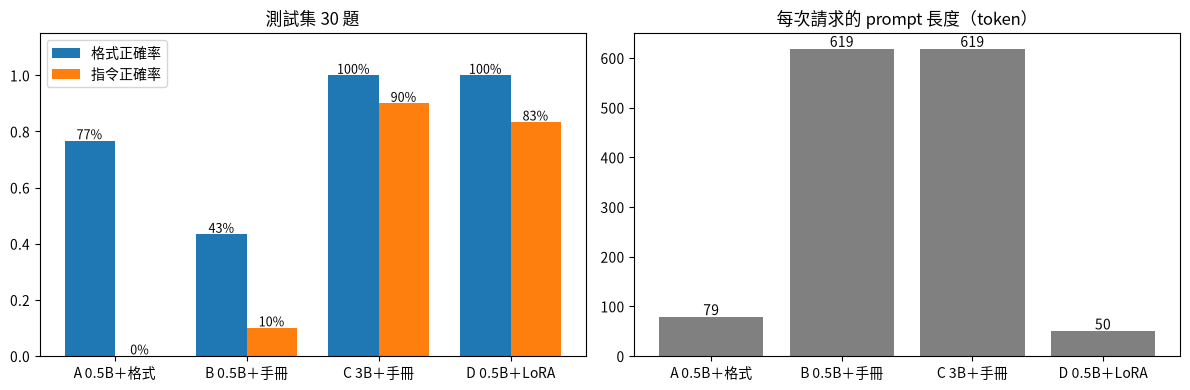

In [7]:
import matplotlib.pyplot as plt
import numpy as np

from course_utils.viz import setup_cjk

setup_cjk()
names = list(results)
x = np.arange(len(names))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

for k, (key, label) in enumerate([("format_ok", "格式正確率"), ("cmd_ok", "指令正確率")]):
    vals = [results[n][key] for n in names]
    bars = ax1.bar(x + (k - 0.5) * 0.38, vals, width=0.38, label=label)
    ax1.bar_label(bars, labels=[f"{v:.0%}" for v in vals], fontsize=9)
ax1.set_xticks(x, names)
ax1.set_ylim(0, 1.15)
ax1.set_title("測試集 30 題")
ax1.legend(loc="upper left")

bars = ax2.bar(x, [results[n]["tokens"] for n in names], color="gray")
ax2.bar_label(bars, fmt="%.0f")
ax2.set_xticks(x, names)
ax2.set_title("每次請求的 prompt 長度（token）")
plt.tight_layout()
plt.show()

## Step 7：讀這張圖

- **A（0.5B＋格式要求）**：大多能照兩行格式，但指令幾乎全錯。它不知道「這個團隊遇到這種症狀先跑什麼」，只能自己編。
- **B（0.5B＋手冊）**：知識給了，分數卻沒變好，格式甚至更差：0.5B 讀不懂這麼長的 prompt，常常去模仿範例的「症狀：…輸出：…」排版。小模型照長 prompt 做事的能力很弱。
- **C（3B＋手冊）**：不用訓練就拿到最高分。如果你負擔得起 3B 而且 prompt 長度沒問題，**這個任務根本不需要微調**。
- **D（0.5B＋LoRA）**：格式全對、指令八成多，而且 prompt 不到 C 的十分之一、模型只有 C 的六分之一。

微調買到的主要是**成本**（更小的模型、更短的 prompt、更低的延遲），不是正確率。
正確率想再往上，要嘛換更大的模型，要嘛像 C 一樣把知識放進 prompt；手冊變大時，就改成先檢索相關條目，也就是 RAG。

## Step 8：判斷順序

```
 問題是「不知道」還是「不會說」？
       │
       ├─ 不會說（格式、語氣、固定話術）──► 先寫 prompt＋範例
       │                                     │ 還是不穩，或 prompt 太長太貴
       │                                     ▼
       │                                  微調（LoRA）
       │
       └─ 不知道（公司內部知識、會變動的資料）──► RAG
                                                   │ 知識穩定、檢索結果還是用不好
                                                   ▼
                                                RAG＋微調
```

| 情況 | 先選 | 理由 |
|---|---|---|
| 知識常變（工單、文件、價格） | RAG | 改資料不用重訓；回答可以附出處 |
| 輸出格式、語氣要固定 | prompt，不夠再微調 | 本 notebook 的格式正確率差異就在這裡 |
| 每次都要帶一大段固定說明 | 微調 | 把說明「燒進」權重，每次請求省下幾百個 token |
| 要換成更小、更便宜的模型 | 微調 | 小模型照 prompt 做的能力弱，用資料教比較可靠 |
| 需要可追溯、可稽核的答案 | RAG | 微調後的知識藏在權重裡，說不出來源 |

微調**不是**用來塞知識的首選：Lab 6-01 Step 9 看到了，訓練資料沒涵蓋的說法它照樣會猜錯，而且猜錯時格式一樣漂亮。

## 試試看

1. 把 Step 3 的手冊刪掉一半類別，B 和 C 的指令正確率會掉多少？D 會受影響嗎？
2. 把 D 也加上 `WITH_RUNBOOK` 當 system prompt（注意：這跟訓練時的格式不同），分數會更好還是更差？
3. 想一個你工作上的任務，用 Step 8 的判斷順序走一遍：你會停在哪一層？

## 小結

- 格式問題先用 prompt 試；知識問題先用 RAG。微調排最後，因為它要資料、要 GPU、要重訓才能更新。
- 微調買到的是：小模型也能穩定照格式、每次請求不用帶長 prompt、延遲與成本更低。
- 模組 6 到此結束；下一個模組把工具接到 agent 上：MCP。